# Marx binary and ternary breakthrough/temperature comparisons

This single plotting notebook shows Figure 16 and Figure 17 first, followed by every binary and ternary simulation in consecutive six-run batches. Ruptura results use solid lines and every native output point over the complete simulated duration; all 60 PDF-digitized references use their original 50 open-marker points. No curve is interpolated. All dimensions use SI units, and every figure is saved as PDF and PNG at 12 in width.


## 1. Imports, paths, and global style

Typography uses 10 pt tick labels and 11 pt axis labels, experiment titles, and legends.


In [1]:
from pathlib import Path
from functools import lru_cache
import json
import mmap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


cwd = Path.cwd().resolve()
if (cwd / "ternary").is_dir() and (cwd / "base.json").is_file():
    MARX2_DIR = cwd
elif (cwd / "marx2" / "ternary").is_dir():
    MARX2_DIR = cwd / "marx2"
else:
    raise FileNotFoundError("Run this notebook from marx2/ or the repository root.")

REFERENCE_ROOT = MARX2_DIR / "reference_digitized"
PDF_DIR = MARX2_DIR / "output" / "pdf"
PNG_DIR = MARX2_DIR / "figures"
PDF_DIR.mkdir(parents=True, exist_ok=True)
PNG_DIR.mkdir(exist_ok=True)

N_REFERENCE_POINTS = 50
FIGURE_WIDTH = 9.0  # in; the paper prints it at 6.3 in, so 12 pt text prints at about 8 pt
THERMOCOUPLE_POSITION = 1.1  # m, thermocouple T5, whose readings the experiments give

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 12,
    "lines.linewidth": 1.6,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

print(f"Ruptura data:  {MARX2_DIR / 'ternary'}")
print(f"Reference data: {REFERENCE_ROOT}")
print(f"PDF output:      {PDF_DIR}")
print(f"PNG output:      {PNG_DIR}")


Ruptura data:  /Users/youriran/pusan/ruptura/validation/3.3.1_energy_balance_marx_ternary/marx2/ternary
Reference data: /Users/youriran/pusan/ruptura/validation/3.3.1_energy_balance_marx_ternary/marx2/reference_digitized
PDF output:      /Users/youriran/pusan/ruptura/validation/3.3.1_energy_balance_marx_ternary/marx2/output/pdf
PNG output:      /Users/youriran/pusan/ruptura/validation/3.3.1_energy_balance_marx_ternary/marx2/figures


## 2. Run registry and figure groups

All 60 runs use experimental reference traces digitized from the paper PDFs. Figure 16 and Figure 17 remain first; subsequent sections group B and T runs in batches of six.


In [2]:
REFERENCE_RUNS = {
    **{f"B{index}": {"reference": f"B{index}"} for index in range(1, 37)},
    **{f"T{index}": {"reference": f"T{index}"} for index in range(1, 25)},
}

FIGURE_16 = ["T15", "T3", "T13", "T21"]
FIGURE_17 = ["T17", "T5", "T23", "T11"]
BINARY_BATCHES = [
    [f"B{index}" for index in range(start, start + 6)]
    for start in range(1, 37, 6)
]
TERNARY_BATCHES = [
    [f"T{index}" for index in range(start, start + 6)]
    for start in range(1, 25, 6)
]


def inferred_flow_rate_m3_s(velocity_m_s):
    candidates = {1.0e-5: 0.027451748447320297, 2.0e-5: 0.054903496894640594, 3.0e-5: 0.08235524534196088}
    return min(candidates, key=lambda flow: abs(candidates[flow] - velocity_m_s))


def run_metadata(run_id):
    kind = "binary" if run_id.startswith("B") else "ternary"
    sim_dir = MARX2_DIR / kind / run_id
    with (sim_dir / "simulation.json").open() as handle:
        settings = json.load(handle)

    components = []
    for component_index, component in enumerate(settings["Components"]):
        if component.get("CarrierGas", False):
            continue
        components.append({
            "index": component_index,
            "name": component["Name"],
            "fraction_percent": float(component["GasPhaseMolFraction"]),
            "filename": f"component_{component_index}_{component['Name']}.data",
        })

    flow_m3_s = inferred_flow_rate_m3_s(float(settings["ColumnEntranceVelocity"]))
    metadata = {
        "kind": kind,
        "sim_dir": sim_dir,
        "components": components,
        "temperature_K": float(settings["InfluxTemperature"]),
        "flow_m3_s": flow_m3_s,
        "pressure_Pa": float(settings["InletPressure"]),
        "simulation_end_s": float(settings["SimulationTime"]),
        # Outputs at t = 0, WriteInterval, ..., SimulationTime.
        "expected_output_points": int(float(settings["SimulationTime"]) // float(settings["WriteInterval"])) + 1,
    }
    metadata.update(REFERENCE_RUNS[run_id])
    return metadata


RUNS = {
    run_id: run_metadata(run_id)
    for run_id in [
        *[f"B{index}" for index in range(1, 37)],
        *[f"T{index}" for index in range(1, 25)],
    ]
}

assert len(RUNS) == 60
assert len(BINARY_BATCHES) == 6
assert len(TERNARY_BATCHES) == 4
print(f"Registered {len(RUNS)} simulations and {len(REFERENCE_RUNS)} reference datasets.")


Registered 60 simulations and 60 reference datasets.


## 3. Native output readers (no interpolation)

Every complete Ruptura outlet history is read and plotted at its native write frequency and full simulated duration. The PDF-digitized references retain their original 50 points.


In [3]:
@lru_cache(maxsize=None)
def data_column_index(path_string, heading):
    """Resolve a one-based Ruptura '# column N:' header to a NumPy index."""
    prefix = heading.casefold()
    with Path(path_string).open("rt", encoding="utf-8") as handle:
        for line in handle:
            if not line.startswith("#"):
                break
            if line.startswith("# column "):
                number_text, description = line[9:].split(":", 1)
                if description.strip().casefold().startswith(prefix):
                    return int(number_text) - 1
    raise ValueError(f"Column heading {heading!r} not found in {path_string}")


@lru_cache(maxsize=None)
def outlet_rows(path_string, min_columns):
    # Parse only the final axial row before each blank-line block separator.
    # The memory map keeps even multi-gigabyte histories memory-efficient.
    rows = []
    with Path(path_string).open("rb") as handle:
        with mmap.mmap(handle.fileno(), length=0, access=mmap.ACCESS_READ) as mapped:
            block_start = 0
            while True:
                block_end = mapped.find(b"\n\n", block_start)
                if block_end < 0:
                    break
                line_start = mapped.rfind(b"\n", block_start, block_end) + 1
                line = mapped[line_start:block_end].strip()
                if line and not line.startswith(b"#"):
                    values = np.fromstring(line.decode("ascii"), sep=" ")
                    if len(values) >= min_columns:
                        rows.append(values[:min_columns])
                block_start = block_end + 2
    if not rows:
        raise ValueError(f"No complete {min_columns}-column blocks found in {path_string}")
    return np.asarray(rows, dtype=float)


@lru_cache(maxsize=None)
def rows_at_position(path_string, position, columns):
    """Every output block interpolated linearly to an axial position; columns are zero-based and include z first."""
    data = pd.read_csv(path_string, comment="#", sep=r"\s+", header=None, usecols=list(columns)).to_numpy()
    order = np.argsort(np.argsort(columns))  # pandas returns the columns in file order
    data = data[:, order]
    z = data[:, 0]
    nodes = int(np.argmax(z[1:] <= z[:-1])) + 1
    blocks = data[: len(data) // nodes * nodes].reshape(-1, nodes, len(columns))
    grid = blocks[0, :, 0]
    k = int(np.searchsorted(grid, position))
    weight = (position - grid[k - 1]) / (grid[k] - grid[k - 1])
    return (1.0 - weight) * blocks[:, k - 1, 1:] + weight * blocks[:, k, 1:]


def first_crossing(x, y, level):
    """First upward crossing of a level, interpolated linearly (digitized curves can start above it)."""
    i = int(np.flatnonzero((y[:-1] < level) & (y[1:] >= level))[0]) + 1
    return x[i - 1] + (level - y[i - 1]) * (x[i] - x[i - 1]) / (y[i] - y[i - 1])


def direct_xy(x, y, source):
    """Return source samples unchanged after basic integrity checks."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if x.shape != y.shape or x.ndim != 1:
        raise ValueError(f"{source}: x and y must be matching one-dimensional arrays")
    if len(x) < 2 or not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError(f"{source}: curve is incomplete or contains non-finite values")
    if np.any(np.diff(x) < 0.0):
        raise ValueError(f"{source}: time values are not ordered")
    return x, y


def load_reference(run_id):
    settings = RUNS[run_id]
    ref_dir = REFERENCE_ROOT / settings["reference"]
    reference = {"temperature": {}}
    for component in settings["components"]:
        species = component["name"]
        raw = np.loadtxt(ref_dir / f"exp-{species}.csv", delimiter=",")
        reference[species] = direct_xy(raw[:, 0], raw[:, 1], f"{run_id} reference {species}")
    raw_temperature = np.loadtxt(ref_dir / "exp-Temp.csv", delimiter=",")
    reference["temperature"]["gas"] = direct_xy(
        raw_temperature[:, 0], raw_temperature[:, 1], f"{run_id} reference temperature"
    )
    # Model curves of Marx et al. (digitize_model.py), ternary runs only.
    reference["model"] = {}
    for name in [component["name"] for component in settings["components"]] + ["Temp"]:
        path = ref_dir / f"model-{name}.csv"
        if path.is_file():
            raw = np.loadtxt(path, delimiter=",")
            reference["model"][name] = direct_xy(raw[:, 0], raw[:, 1], f"{run_id} model of Marx et al. {name}")
    return reference


@lru_cache(maxsize=None)
def load_run(run_id):
    settings = RUNS[run_id]
    reference = load_reference(run_id)

    sim_dir = settings["sim_dir"]
    column_path = (sim_dir / "column.data").resolve()
    column_time_index = data_column_index(str(column_path), "Time, t")
    temperature_indices = {
        "gas": data_column_index(str(column_path), "Gas temperature,"),
        "solid": data_column_index(str(column_path), "Solid temperature,"),
        "wall": data_column_index(str(column_path), "Wall temperature,"),
    }
    # The temperatures at the thermocouple T5 (1.1 m), as in the experiments.
    position_index = data_column_index(str(column_path), "Column position, z")
    profile = rows_at_position(
        str(column_path), THERMOCOUPLE_POSITION, (position_index, column_time_index, *temperature_indices.values())
    )
    column = np.column_stack((profile[:, 0], *[profile[:, 1 + k] for k in range(len(temperature_indices))]))
    time_s = 60.0 * column[:, 0]
    if len(time_s) != settings["expected_output_points"]:
        raise RuntimeError(
            f"{run_id}: expected {settings['expected_output_points']} column outputs, "
            f"found {len(time_s)}. Rerun this case."
        )
    time_s, _ = direct_xy(time_s, time_s, f"{run_id} column time")

    simulation = {"temperature": {}}
    for component in settings["components"]:
        component_path = (sim_dir / component["filename"]).resolve()
        component_time_index = data_column_index(str(component_path), "Time, t")
        mole_fraction_index = data_column_index(str(component_path), "Mole fraction,")
        rows = outlet_rows(str(component_path), min_columns=max(component_time_index, mole_fraction_index) + 1)
        component_time_s = 60.0 * rows[:, component_time_index]
        if len(component_time_s) != settings["expected_output_points"]:
            raise RuntimeError(
                f"{run_id}/{component['name']}: expected {settings['expected_output_points']} outputs, "
                f"found {len(component_time_s)}."
            )
        simulation[component["name"]] = direct_xy(
            component_time_s,
            rows[:, mole_fraction_index],
            f"{run_id} simulation {component['name']}",
        )
    for k, label in enumerate(temperature_indices):
        simulation["temperature"][label] = direct_xy(
            time_s, column[:, 1 + k], f"{run_id} simulation {label} temperature"
        )
    return simulation, reference


for run_id in RUNS:
    simulation, reference = load_run(run_id)
    for component in RUNS[run_id]["components"]:
        species = component["name"]
        assert len(simulation[species][0]) == RUNS[run_id]["expected_output_points"]
        assert len(reference[species][0]) == N_REFERENCE_POINTS
    for phase in ("gas", "solid", "wall"):
        assert len(simulation["temperature"][phase][0]) == RUNS[run_id]["expected_output_points"]
    assert len(reference["temperature"]["gas"][0]) == N_REFERENCE_POINTS

print(
    f"Validated {len(RUNS)} simulations using every native Ruptura output point; "
    f"each reference curve retains its {N_REFERENCE_POINTS} digitized points."
)


Validated 60 simulations using every native Ruptura output point; each reference curve retains its 50 digitized points.


## 4. Plotting utilities

Legends list all Ruptura handles first and all available reference handles second.


In [4]:
SPECIES_STYLE = {
    "H2":  {"color": "C0", "marker": "s", "label": r"H$_2$"},
    "N2":  {"color": "C1", "marker": "D", "label": r"N$_2$"},
    "CO2": {"color": "C2", "marker": "o", "label": r"CO$_2$"},
}
TEMPERATURE_STYLE = {
    "gas":   {"color": "C3", "label": "Gas"},
    "solid": {"color": "C4", "label": "Solid"},
    "wall":  {"color": "C5", "label": "Wall"},
}


def experiment_title(run_id):
    settings = RUNS[run_id]
    names = "/".join(component["name"] for component in settings["components"])
    mix = "/".join(f"{component['fraction_percent'] / 100:.2f}" for component in settings["components"])
    pressure_mpa = settings["pressure_Pa"] / 1.0e6
    flow_coefficient = settings["flow_m3_s"] / 1.0e-5
    return (
        rf"{run_id}: $T_0={settings['temperature_K']:.0f}$ K, $p_0={pressure_mpa:.1f}$ MPa"
        "\n" + rf"$\dot{{V}}={flow_coefficient:.1f}\times10^{{-5}}$ m$^3$ s$^{{-1}}$"
        "\n" + rf"$\boldsymbol{{y}}_{{\mathrm{{{names}}}}}={mix}$"
    )


def style_axes(ax):
    ax.tick_params(axis="both", which="both", labelsize=10)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)


def plot_experiment(run_id, ax_breakthrough, ax_temperature):
    settings = RUNS[run_id]
    simulation, reference = load_run(run_id)
    all_times = []

    for component in settings["components"]:
        species = component["name"]
        style = SPECIES_STYLE[species]
        x_sim, y_sim = simulation[species]
        ax_breakthrough.plot(x_sim, y_sim, color=style["color"], linestyle="-")
        # all_times.append(x_sim[-1])
        if reference:
            x_ref, y_ref = reference[species]
            ax_breakthrough.plot(
                x_ref, y_ref, linestyle="None", marker=style["marker"], markersize=3.4,
                markerfacecolor="none", markeredgecolor=style["color"], markeredgewidth=0.9,
            )
            all_times.append(x_ref[-1])
        if species in reference.get("model", {}):
            ax_breakthrough.plot(*reference["model"][species], color=style["color"], linestyle=":", linewidth=1.4)

    for phase, style in TEMPERATURE_STYLE.items():
        x_sim, y_sim = simulation["temperature"][phase]
        ax_temperature.plot(x_sim, y_sim, color=style["color"], linestyle="-")
        # all_times.append(x_sim[-1])

    temperature_series = [simulation["temperature"][phase][1] for phase in TEMPERATURE_STYLE]
    if reference:
        x_ref_temp, y_ref_temp = reference["temperature"]["gas"]
        ax_temperature.plot(
            x_ref_temp, y_ref_temp, linestyle="None", marker="s", markersize=3.4,
            markerfacecolor="none", markeredgecolor=TEMPERATURE_STYLE["gas"]["color"], markeredgewidth=0.9,
        )
        all_times.append(x_ref_temp[-1])
        temperature_series.append(y_ref_temp)
        if "Temp" in reference.get("model", {}):
            ax_temperature.plot(*reference["model"]["Temp"], color=TEMPERATURE_STYLE["gas"]["color"], linestyle=":",
                                linewidth=1.4)

    ax_breakthrough.set_title(experiment_title(run_id), fontsize=12, pad=4)
    ax_breakthrough.set_ylabel("Mole fraction,\n" r"$y_i$ / [-]", fontsize=12)
    ax_breakthrough.set_ylim(-0.04, 1.05)
    ax_breakthrough.tick_params(labelbottom=False)

    temp_min = min(float(np.nanmin(values)) for values in temperature_series)
    temp_max = max(float(np.nanmax(values)) for values in temperature_series)
    padding = max(1.0, 0.06 * (temp_max - temp_min))
    ax_temperature.set_ylim(temp_min - padding, temp_max + padding)
    ax_temperature.set_xlim(0.0, 2 * max(all_times))
    ax_temperature.set_ylabel("Temperature,\n" r"$T$ / K", fontsize=12)
    ax_temperature.set_xlabel(r"Time, $t$ / s", fontsize=12)
    style_axes(ax_breakthrough)
    style_axes(ax_temperature)


def legend_handles(species, include_reference):
    # Required order: every Ruptura handle first, followed by references.
    mole_handles = [
        Line2D([], [], color=SPECIES_STYLE[name]["color"], linestyle="-")
        for name in species
    ]
    mole_labels = [f"RUPTURA {SPECIES_STYLE[name]['label']}" for name in species]
    if include_reference:
        mole_handles.extend([
            Line2D([], [], color=SPECIES_STYLE[name]["color"], linestyle="None",
                   marker=SPECIES_STYLE[name]["marker"], markerfacecolor="none",
                   markeredgewidth=0.9, markersize=5)
            for name in species
        ])
        mole_labels.extend([f"Experiment {SPECIES_STYLE[name]['label']}" for name in species])
        mole_handles.append(Line2D([], [], color="0.3", linestyle=":", linewidth=1.4))
        mole_labels.append("Model of Marx et al.")

    temperature_handles = [
        Line2D([], [], color=style["color"], linestyle="-")
        for style in TEMPERATURE_STYLE.values()
    ]
    temperature_labels = [f"RUPTURA {style['label'].lower()}" for style in TEMPERATURE_STYLE.values()]
    if include_reference:
        temperature_handles.append(
            Line2D([], [], color=TEMPERATURE_STYLE["gas"]["color"], linestyle="None", marker="s",
                   markerfacecolor="none", markeredgewidth=0.9, markersize=5)
        )
        temperature_labels.append("Experiment")
        temperature_handles.append(Line2D([], [], color=TEMPERATURE_STYLE["gas"]["color"], linestyle=":", linewidth=1.4))
        temperature_labels.append("Model of Marx et al.")
    return mole_handles, mole_labels, temperature_handles, temperature_labels


def make_comparison_figure(run_ids, nrows, ncols, stem):
    if len(run_ids) != nrows * ncols:
        raise ValueError("The run count must fill the requested grid.")

    # Panels in nrows x ncols, both legends in a row below them (at 9 in wide, the paper prints 12 pt as 8 pt).
    fig = plt.figure(figsize=(FIGURE_WIDTH, 3.3 * nrows + 1.7), constrained_layout=True)
    outer = fig.add_gridspec(
        nrows + 1, ncols, height_ratios=[1.0] * nrows + [1.7 / 3.3], wspace=0.08, hspace=0.10
    )
    axes = []
    for index, run_id in enumerate(run_ids):
        row, column = divmod(index, ncols)
        pair = outer[row, column].subgridspec(2, 1, hspace=0.05)
        ax_top = fig.add_subplot(pair[0])
        ax_bottom = fig.add_subplot(pair[1], sharex=ax_top)
        plot_experiment(run_id, ax_top, ax_bottom)
        axes.append((ax_top, ax_bottom))

    species = [
        name for name in ("H2", "N2", "CO2")
        if any(name in [component["name"] for component in RUNS[run_id]["components"]] for run_id in run_ids)
    ]
    include_reference = True
    legend_grid = outer[nrows, :].subgridspec(1, 2, width_ratios=[1.0, 1.0], wspace=0.05)
    legend_mole_ax = fig.add_subplot(legend_grid[0])
    legend_temp_ax = fig.add_subplot(legend_grid[1])
    for legend_ax in (legend_mole_ax, legend_temp_ax):
        legend_ax.axis("off")
    mole_h, mole_l, temp_h, temp_l = legend_handles(species, include_reference)
    legend_mole_ax.legend(mole_h, mole_l, loc="center", frameon=True, title="Mole fractions", fontsize=12, ncol=2)
    legend_temp_ax.legend(temp_h, temp_l, loc="center", frameon=True, title="Temperature at 1.1 m", fontsize=12, ncol=2)

    pdf_path = PDF_DIR / f"marx_{stem}.pdf"
    png_path = PNG_DIR / f"marx_{stem}.png"
    fig.savefig(pdf_path)
    fig.savefig(png_path, dpi=200)
    print(f"Saved {pdf_path.name} and {png_path.name} at {FIGURE_WIDTH:g} in width")
    return fig, axes


## 5. Figure 16

Source Figure 16 experiments from the supplied table.


Saved marx_figure_16.pdf and marx_figure_16.png at 9 in width


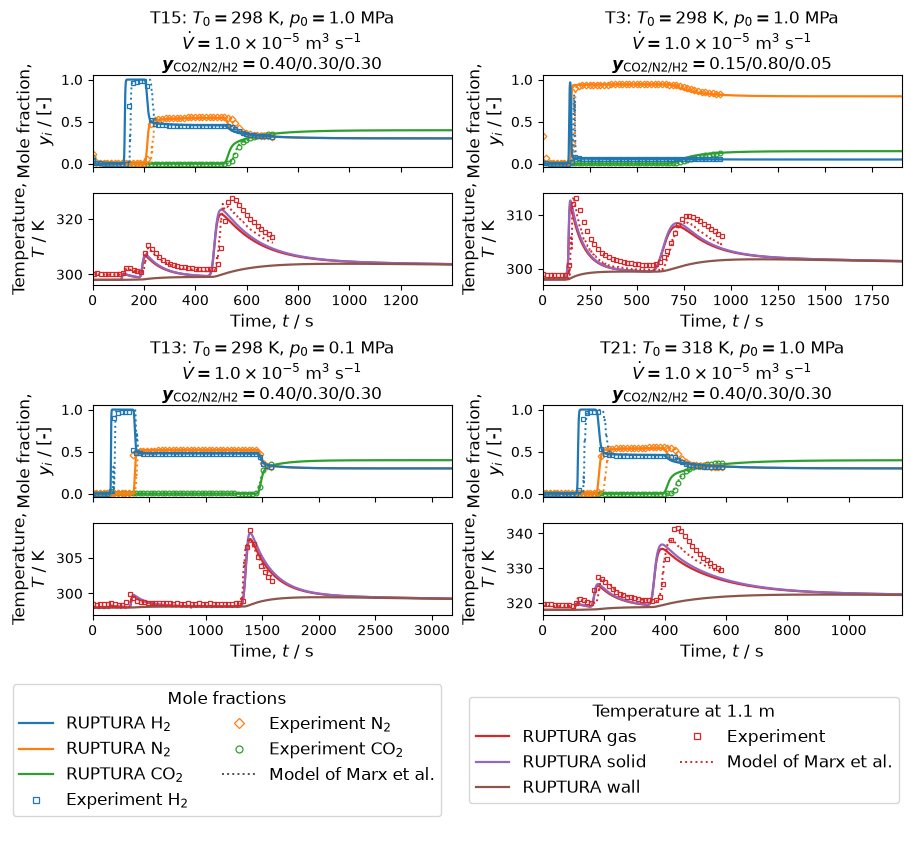

In [5]:
fig_figure_16, axes_figure_16 = make_comparison_figure(
    FIGURE_16, nrows=2, ncols=2, stem='figure_16'
)
plt.show()


## 6. Figure 17

Source Figure 17 experiments from the supplied table.


Saved marx_figure_17.pdf and marx_figure_17.png at 9 in width


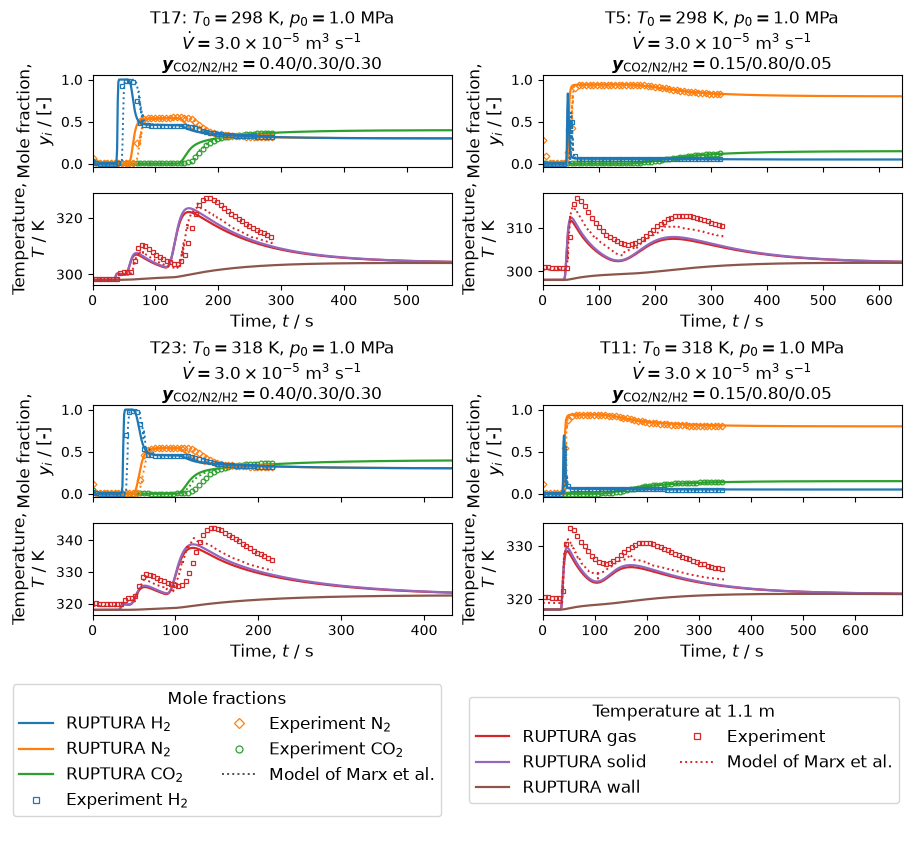

In [6]:
fig_figure_17, axes_figure_17 = make_comparison_figure(
    FIGURE_17, nrows=2, ncols=2, stem='figure_17'
)
plt.show()


## 7. Binary runs B1-B6

Binary simulations B1 through B6 in a 2 row by 3 column layout.


Saved marx_B1_B6.pdf and marx_B1_B6.png at 9 in width


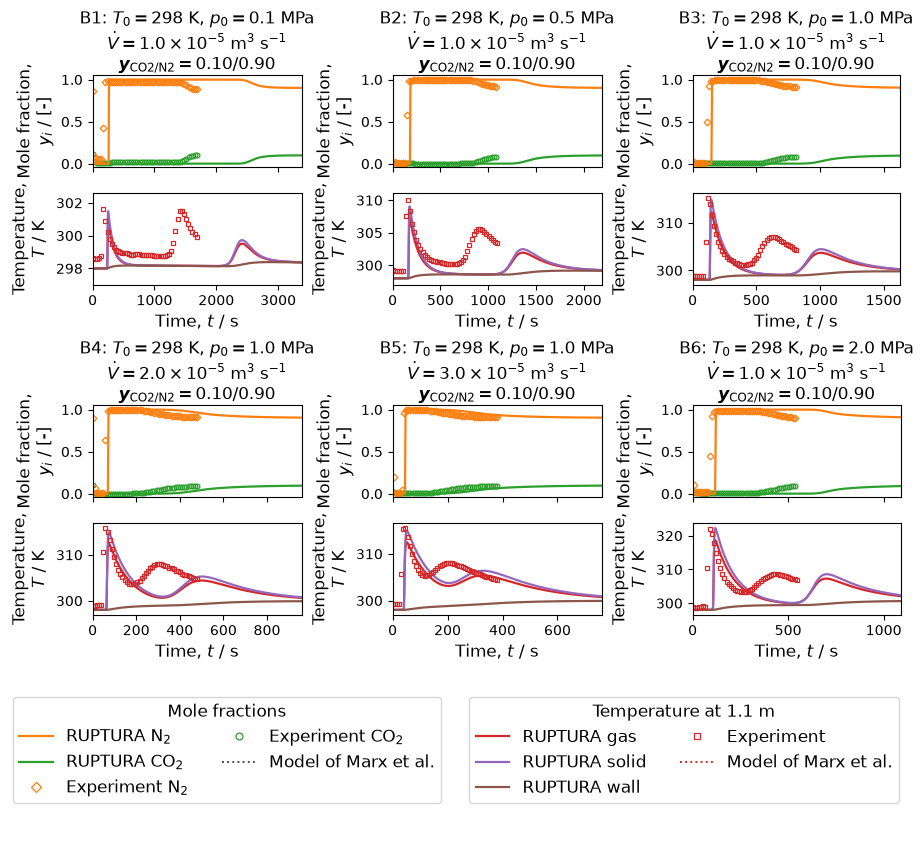

In [7]:
fig_b1_b6, axes_b1_b6 = make_comparison_figure(
    ['B1', 'B2', 'B3', 'B4', 'B5', 'B6'], nrows=2, ncols=3, stem='B1_B6'
)
plt.show()


## 8. Binary runs B7-B12

Binary simulations B7 through B12 in a 2 row by 3 column layout.


Saved marx_B7_B12.pdf and marx_B7_B12.png at 9 in width


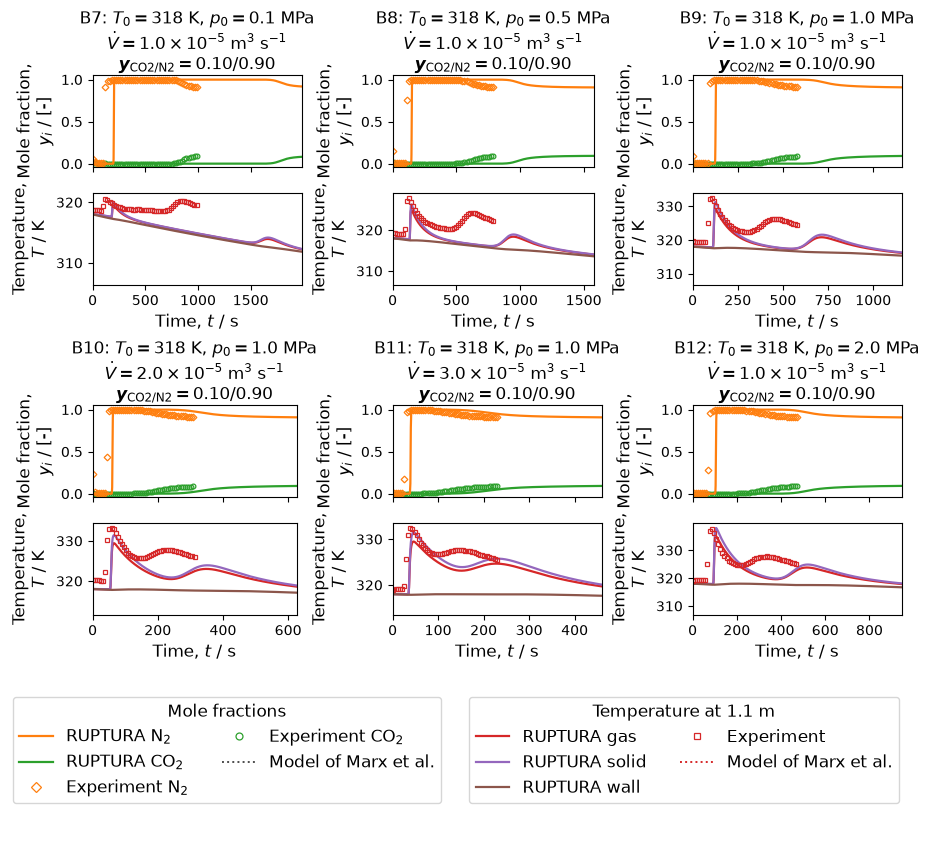

In [8]:
fig_b7_b12, axes_b7_b12 = make_comparison_figure(
    ['B7', 'B8', 'B9', 'B10', 'B11', 'B12'], nrows=2, ncols=3, stem='B7_B12'
)
plt.show()


## 9. Binary runs B13-B18

Binary simulations B13 through B18 in a 2 row by 3 column layout.


Saved marx_B13_B18.pdf and marx_B13_B18.png at 9 in width


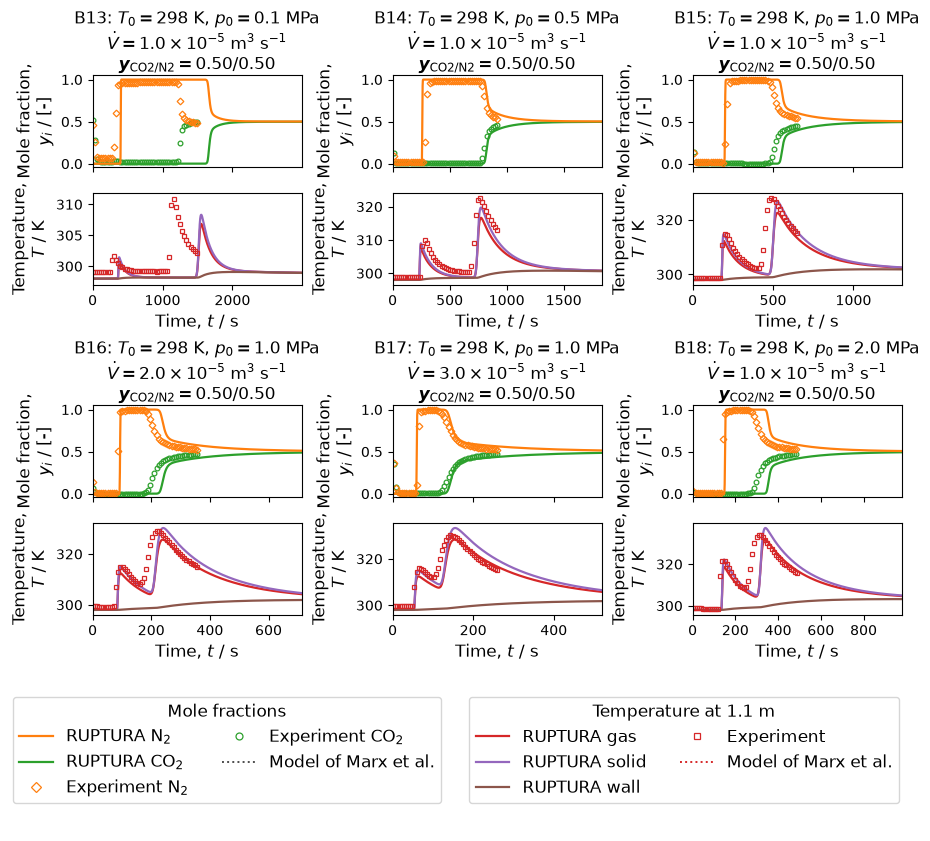

In [9]:
fig_b13_b18, axes_b13_b18 = make_comparison_figure(
    ['B13', 'B14', 'B15', 'B16', 'B17', 'B18'], nrows=2, ncols=3, stem='B13_B18'
)
plt.show()


## 10. Binary runs B19-B24

Binary simulations B19 through B24 in a 2 row by 3 column layout.


Saved marx_B19_B24.pdf and marx_B19_B24.png at 9 in width


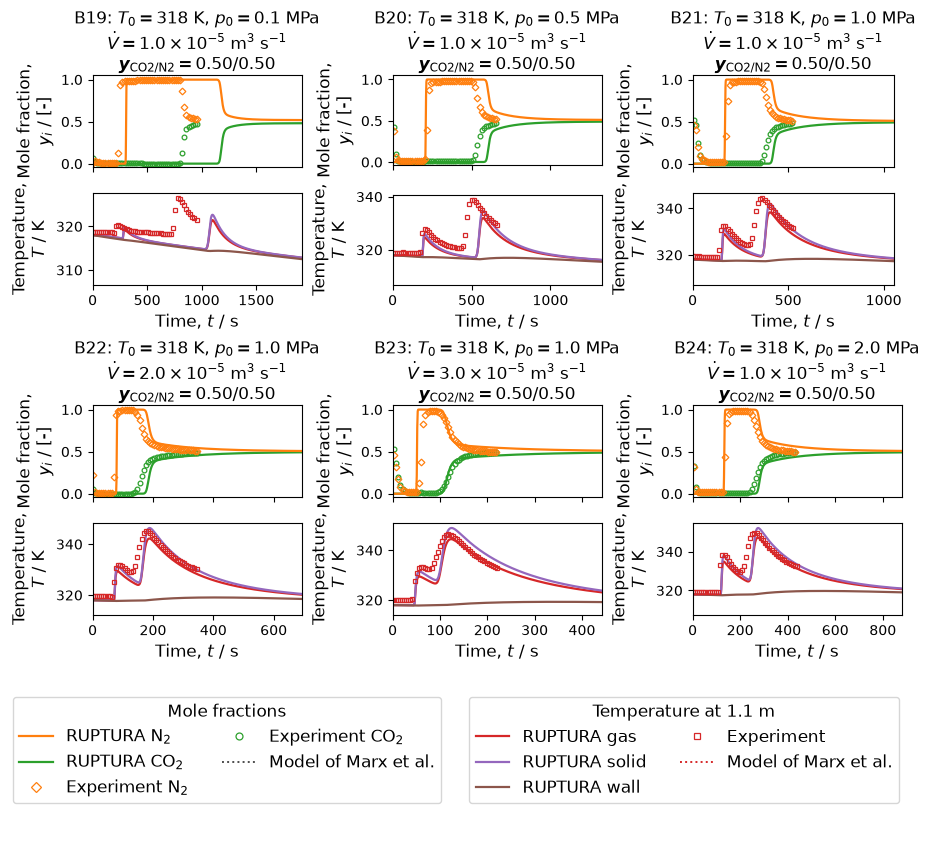

In [10]:
fig_b19_b24, axes_b19_b24 = make_comparison_figure(
    ['B19', 'B20', 'B21', 'B22', 'B23', 'B24'], nrows=2, ncols=3, stem='B19_B24'
)
plt.show()


## 11. Binary runs B25-B30

Binary simulations B25 through B30 in a 2 row by 3 column layout.


Saved marx_B25_B30.pdf and marx_B25_B30.png at 9 in width


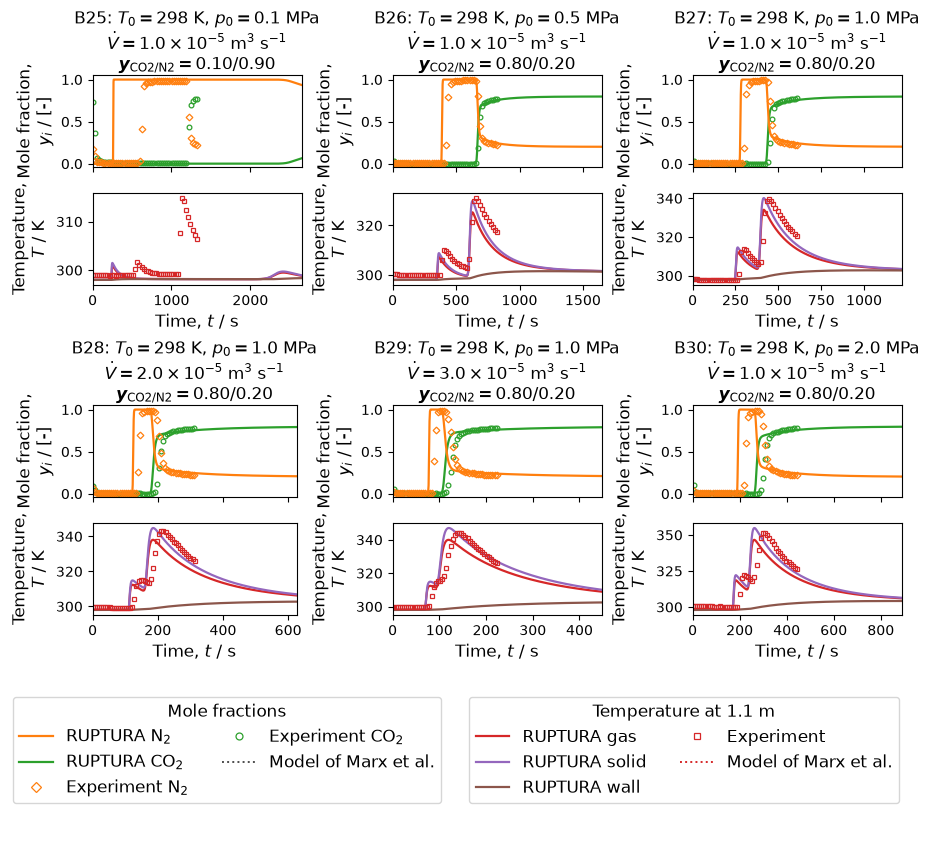

In [11]:
fig_b25_b30, axes_b25_b30 = make_comparison_figure(
    ['B25', 'B26', 'B27', 'B28', 'B29', 'B30'], nrows=2, ncols=3, stem='B25_B30'
)
plt.show()


## 12. Binary runs B31-B36

Binary simulations B31 through B36 in a 2 row by 3 column layout.


Saved marx_B31_B36.pdf and marx_B31_B36.png at 9 in width


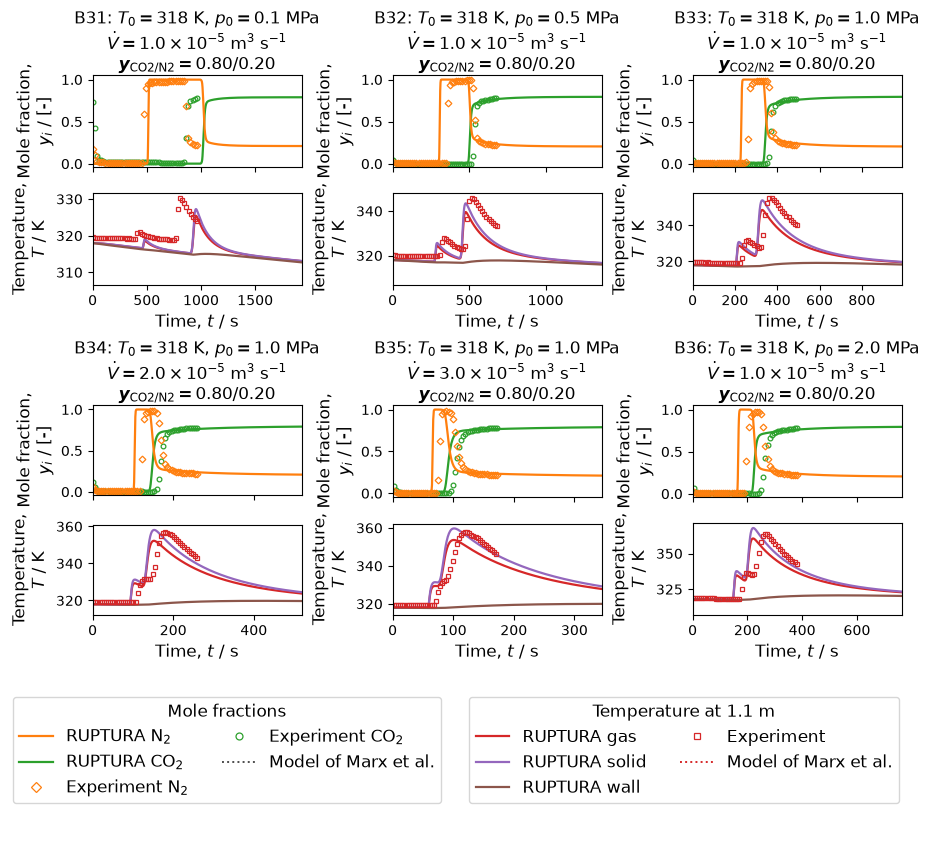

In [12]:
fig_b31_b36, axes_b31_b36 = make_comparison_figure(
    ['B31', 'B32', 'B33', 'B34', 'B35', 'B36'], nrows=2, ncols=3, stem='B31_B36'
)
plt.show()


## 13. Ternary runs T1-T6

Ternary simulations T1 through T6 in a 2 row by 3 column layout.


Saved marx_T1_T6.pdf and marx_T1_T6.png at 9 in width


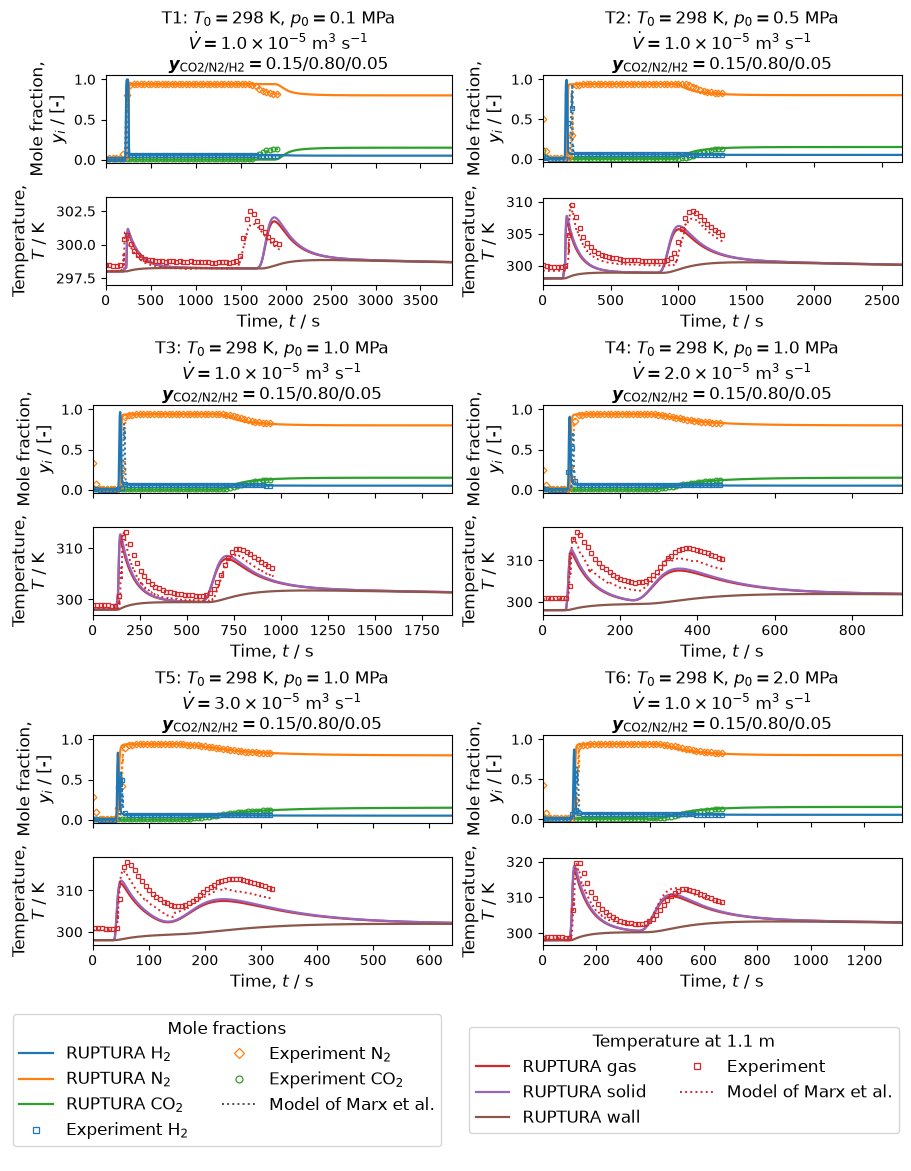

In [13]:
fig_t1_t6, axes_t1_t6 = make_comparison_figure(
    ['T1', 'T2', 'T3', 'T4', 'T5', 'T6'], nrows=3, ncols=2, stem='T1_T6'
)
plt.show()


## 14. Ternary runs T7-T12

Ternary simulations T7 through T12 in a 2 row by 3 column layout.


Saved marx_T7_T12.pdf and marx_T7_T12.png at 9 in width


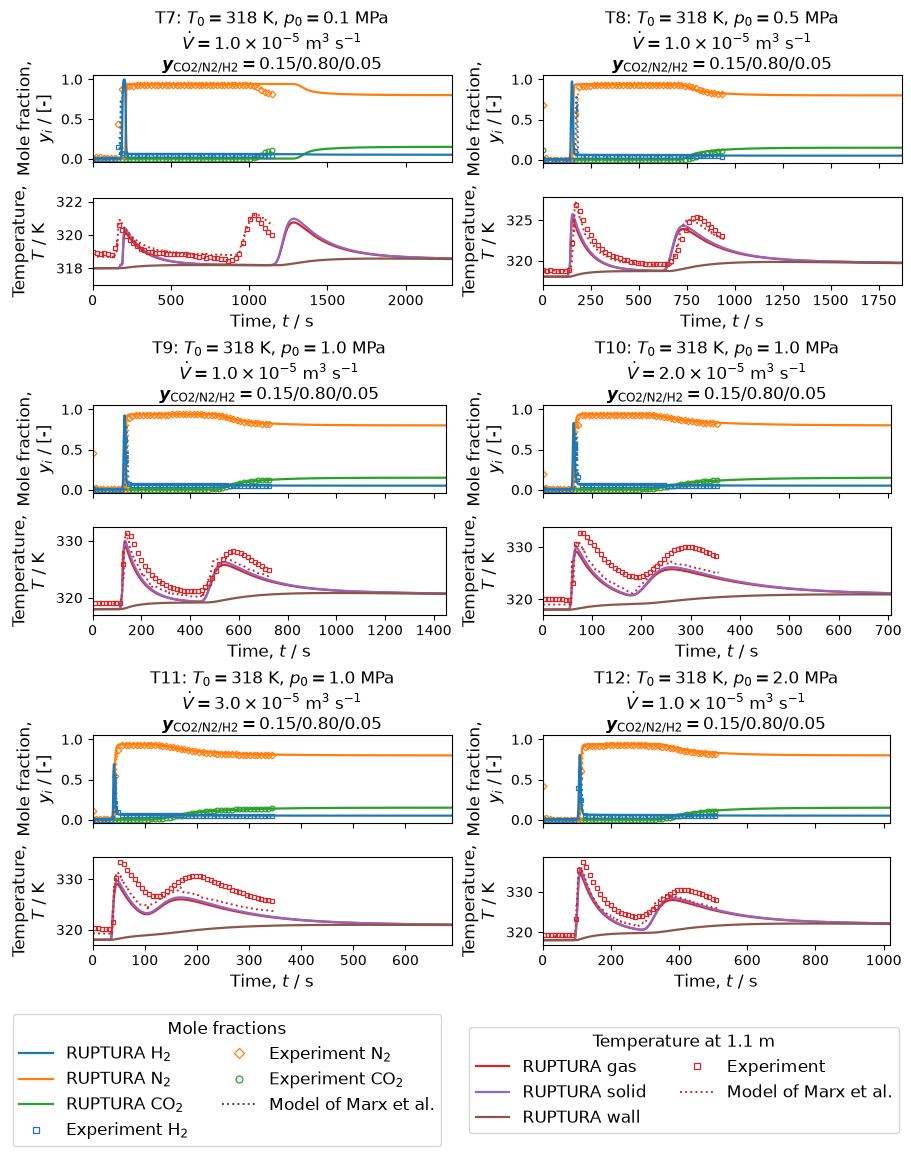

In [14]:
fig_t7_t12, axes_t7_t12 = make_comparison_figure(
    ['T7', 'T8', 'T9', 'T10', 'T11', 'T12'], nrows=3, ncols=2, stem='T7_T12'
)
plt.show()


## 15. Ternary runs T13-T18

Ternary simulations T13 through T18 in a 2 row by 3 column layout.


Saved marx_T13_T18.pdf and marx_T13_T18.png at 9 in width


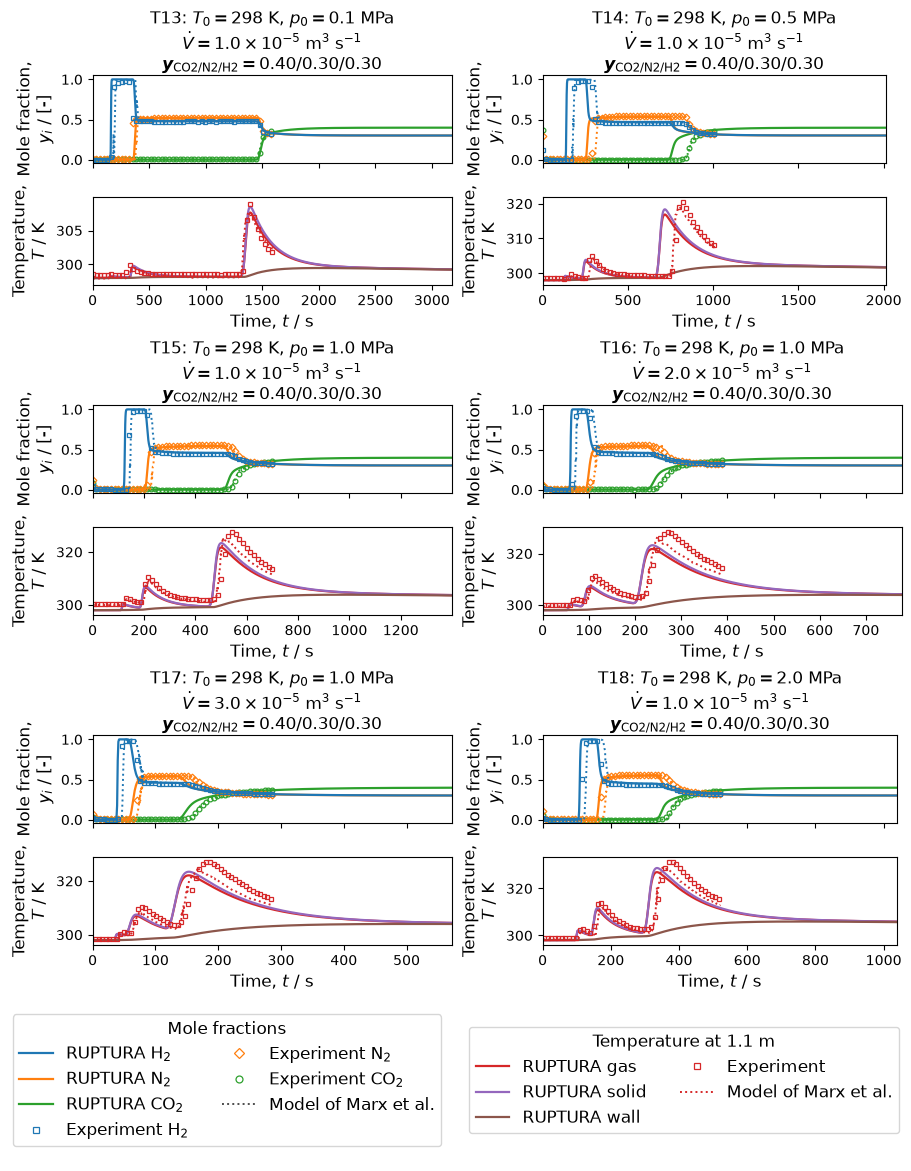

In [15]:
fig_t13_t18, axes_t13_t18 = make_comparison_figure(
    ['T13', 'T14', 'T15', 'T16', 'T17', 'T18'], nrows=3, ncols=2, stem='T13_T18'
)
plt.show()


## 16. Ternary runs T19-T24

Ternary simulations T19 through T24 in a 2 row by 3 column layout.


Saved marx_T19_T24.pdf and marx_T19_T24.png at 9 in width


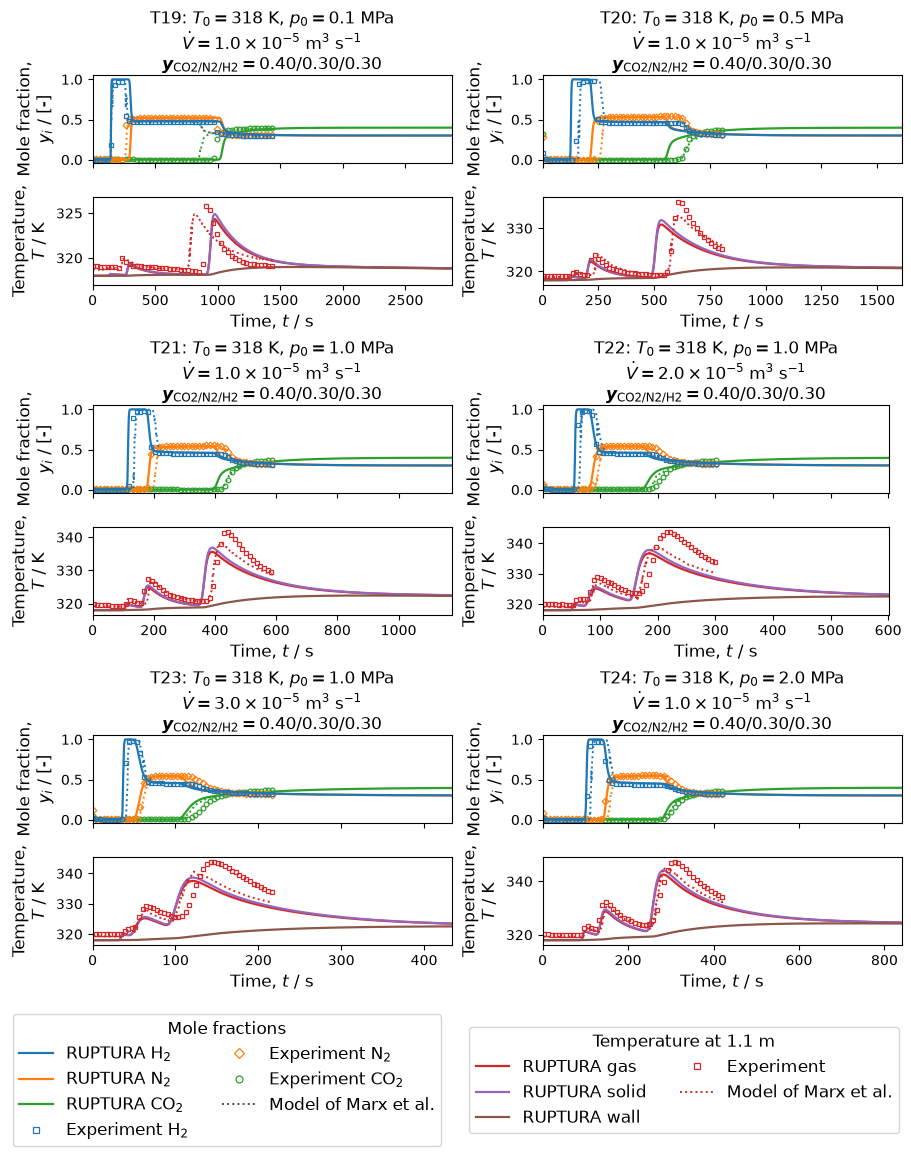

In [16]:
fig_t19_t24, axes_t19_t24 = make_comparison_figure(
    ['T19', 'T20', 'T21', 'T22', 'T23', 'T24'], nrows=3, ncols=2, stem='T19_T24'
)
plt.show()


## 17. Output validation

Confirm that every requested PDF and PNG exists and is nonempty.


## Breakthrough times and largest temperatures of T1–T24


In [17]:
# CO2 breakthrough times t50 (first rise through half the feed value) and largest temperatures at 1.1 m:
# RUPTURA, the model of Marx et al., and the experiment (SI table tab:marx_t50_comparison).
rows = []
for run_id in [f"T{index}" for index in range(1, 25)]:
    simulation, reference = load_run(run_id)
    feed = {component["name"]: component["fraction_percent"] / 100.0 for component in RUNS[run_id]["components"]}
    half = 0.5 * feed["CO2"]
    t50 = {source: first_crossing(*curves["CO2"], half)
           for source, curves in (("ruptura", simulation), ("marx", reference["model"]), ("experiment", reference))}
    rows.append({
        "run": run_id, "feed": "15/80/5" if half < 0.1 else "40/30/30",
        "t50_ruptura": t50["ruptura"], "t50_marx": t50["marx"], "t50_experiment": t50["experiment"],
        "ratio": t50["ruptura"] / t50["experiment"],
        "T_gas": simulation["temperature"]["gas"][1].max(), "T_solid": simulation["temperature"]["solid"][1].max(),
        "T_marx": reference["model"]["Temp"][1].max(), "T_experiment": reference["temperature"]["gas"][1].max(),
    })
t50_table = pd.DataFrame(rows)
t50_table.to_csv(MARX2_DIR / "t50_comparison.csv", index=False, float_format="%.6g")
for row in t50_table.itertuples():
    print(f"{row.run:3s} & {row.feed:8s} & {row.t50_ruptura:.0f} & {row.t50_marx:.0f} & {row.t50_experiment:.0f} & "
          f"{row.ratio:.2f} & {row.T_gas:.1f} & {row.T_solid:.1f} & {row.T_marx:.1f} & {row.T_experiment:.1f} \\\\")


T1  & 15/80/5  & 2005 & 1730 & 1717 & 1.17 & 301.7 & 302.0 & 301.6 & 302.5 \\
T2  & 15/80/5  & 1079 & 1176 & 1157 & 0.93 & 307.1 & 307.8 & 309.7 & 309.6 \\
T3  & 15/80/5  & 769 & 804 & 809 & 0.95 & 311.7 & 312.7 & 313.1 & 313.1 \\
T4  & 15/80/5  & 370 & 372 & 373 & 0.99 & 311.7 & 312.5 & 315.2 & 316.8 \\
T5  & 15/80/5  & 240 & 246 & 242 & 0.99 & 311.6 & 312.4 & 314.8 & 316.9 \\
T6  & 15/80/5  & 518 & 522 & 549 & 0.94 & 317.6 & 318.8 & 319.3 & 319.7 \\
T7  & 15/80/5  & 1369 & 1117 & 1095 & 1.25 & 320.7 & 321.0 & 321.2 & 321.2 \\
T8  & 15/80/5  & 792 & 846 & 847 & 0.94 & 325.2 & 325.7 & 327.2 & 326.8 \\
T9  & 15/80/5  & 589 & 580 & 598 & 0.99 & 329.2 & 330.0 & 331.2 & 331.3 \\
T10 & 15/80/5  & 281 & 281 & 287 & 0.98 & 329.1 & 329.8 & 331.1 & 332.8 \\
T11 & 15/80/5  & 181 & 180 & 187 & 0.97 & 329.0 & 329.7 & 331.3 & 333.3 \\
T12 & 15/80/5  & 418 & 421 & 433 & 0.97 & 334.5 & 335.5 & 336.3 & 337.4 \\
T13 & 40/30/30 & 1498 & 1491 & 1496 & 1.00 & 307.6 & 308.5 & 307.6 & 308.9 \\
T14 & 40/30/3

In [18]:
expected_stems = ['figure_16', 'figure_17', 'B1_B6', 'B7_B12', 'B13_B18', 'B19_B24', 'B25_B30', 'B31_B36', 'T1_T6', 'T7_T12', 'T13_T18', 'T19_T24']

for stem in expected_stems:
    for directory, suffix in ((PDF_DIR, '.pdf'), (PNG_DIR, '.png')):
        path = directory / f'{stem}{suffix}'
        assert path.is_file() and path.stat().st_size > 0, path
        print(f'{path.name:28s} {path.stat().st_size / 1024:9.1f} KiB')


figure_16.pdf                     51.7 KiB
figure_16.png                    399.6 KiB
figure_17.pdf                     46.9 KiB
figure_17.png                    409.9 KiB
B1_B6.pdf                         53.8 KiB
B1_B6.png                        445.7 KiB
B7_B12.pdf                        53.8 KiB
B7_B12.png                       427.6 KiB
B13_B18.pdf                       56.8 KiB
B13_B18.png                      481.9 KiB
B19_B24.pdf                       54.6 KiB
B19_B24.png                      488.0 KiB
B25_B30.pdf                       52.0 KiB
B25_B30.png                      447.1 KiB
B31_B36.pdf                       53.5 KiB
B31_B36.png                      453.2 KiB
T1_T6.pdf                         61.9 KiB
T1_T6.png                        473.4 KiB
T7_T12.pdf                        59.1 KiB
T7_T12.png                       483.7 KiB
T13_T18.pdf                       64.9 KiB
T13_T18.png                      511.6 KiB
T19_T24.pdf                       62.6 KiB
T19_T24.png